# BUSI 乳腺超声图像分割

本 Notebook 演示：数据探索 → 模型构建 → 权重加载 → 预测可视化 → 性能对比。

使用前请确保：

1. BUSI 数据集已解压到 `data/Dataset_BUSI_with_GT/`；
2. 已安装依赖（`pip install -r requirements.txt`）；
3. 如需加载权重，先运行 `python -m src.compare --epochs 100` 完成训练。


In [1]:
%matplotlib inline
import sys
from pathlib import Path
from collections import Counter

# 自动定位项目根目录（向上查找同时包含 src/ 与 data/ 的目录）
def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "src").exists():
            return p
    return Path.cwd()

ROOT = find_root()
sys.path.insert(0, str(ROOT))
print("项目根目录:", ROOT)

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src.config import Config
from src.dataset import collect_samples, split_samples, BUSIDataset, CLASSES
from src.models import build_model
from src.metrics import MetricsTracker
from src.utils import set_seed, get_device, count_parameters

set_seed(42)
device = get_device()
print("设备:", device)

# ---- 可视化辅助函数 ----
def denorm(tensor):
    # 把归一化张量 [C,H,W] 转回 0~1 的 [H,W,C] numpy 图像
    img = tensor.detach().cpu().clone()
    for t, m, s in zip(img, [0.5, 0.5, 0.5], [0.5, 0.5, 0.5]):
        t.mul_(s).add_(m)
    return img.clamp_(0, 1).permute(1, 2, 0).numpy()

def overlay(image, mask, color=(1, 0, 0), alpha=0.45):
    # 在图像上叠加彩色 mask
    img = np.asarray(image).astype(np.float32)
    if img.max() > 1.0:
        img = img / 255.0
    m = np.asarray(mask).astype(np.float32)
    if m.max() > 1.0:
        m = m / 255.0
    m = m[..., None] if m.ndim == 2 else m
    out = img * (1 - alpha * m) + np.array(color) * (alpha * m)
    return np.clip(out, 0, 1)


项目根目录: e:\jerome\MyCode\BUSI_seg
设备: cuda


## 1. 数据集概览

总Number of samples: 780
各类别数量: {'benign': 437, 'malignant': 210, 'normal': 133}


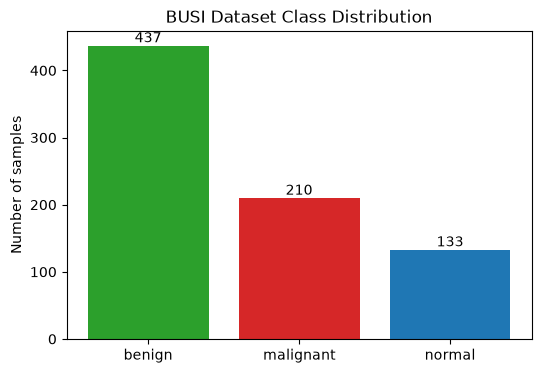

In [2]:
data_root = ROOT / "data" / "Dataset_BUSI_with_GT"
if not data_root.exists():
    print("数据集尚未就绪！请下载 BUSI 数据集并解压到:")
    print("  ", data_root)
    samples = []
else:
    samples = collect_samples(data_root, include_normal=True)
    print("总Number of samples:", len(samples))
    cls_counts = Counter(s["class"] for s in samples)
    print("各类别数量:", dict(cls_counts))

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(list(cls_counts.keys()), list(cls_counts.values()),
           color=["#2ca02c", "#d62728", "#1f77b4"])
    for i, v in enumerate(cls_counts.values()):
        ax.text(i, v, str(v), ha="center", va="bottom")
    ax.set_title("BUSI Dataset Class Distribution")
    ax.set_ylabel("Number of samples")
    plt.show()


### 各类别样本示例

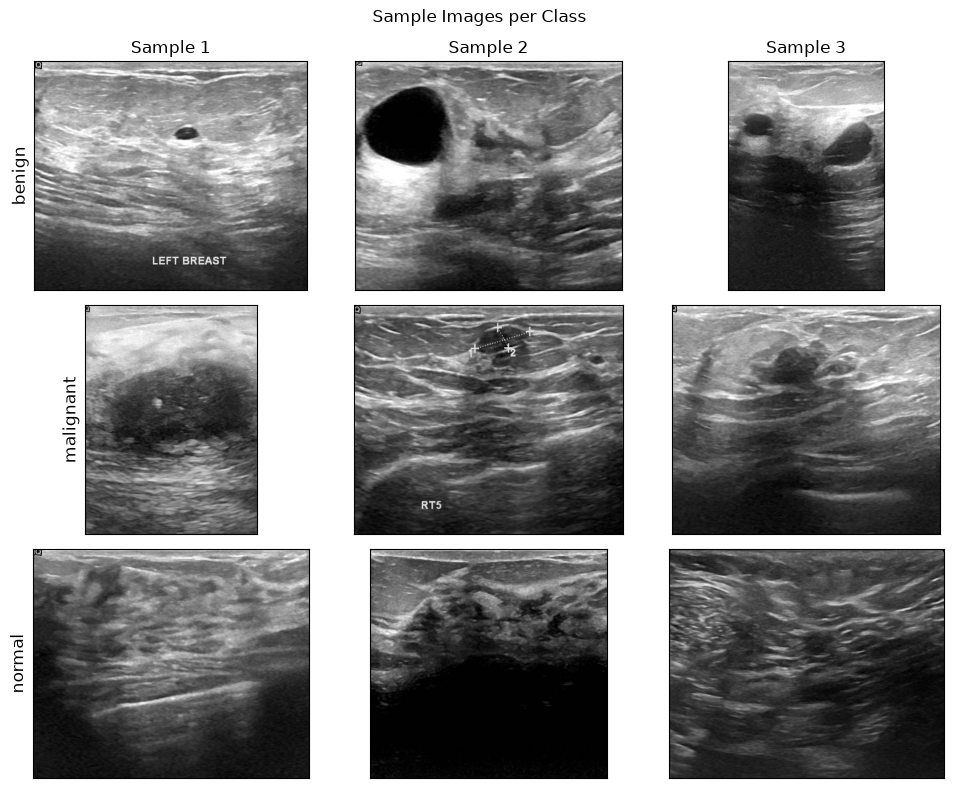

In [3]:
if samples:
    fig, axes = plt.subplots(len(CLASSES), 3, figsize=(10, 8))
    for r, cls in enumerate(CLASSES):
        cls_samples = [s for s in samples if s["class"] == cls][:3]
        for c, s in enumerate(cls_samples):
            img = Image.open(s["image"]).convert("RGB")
            ax = axes[r, c]
            ax.imshow(img)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0:
                ax.set_title(f"Sample {c+1}")
            if c == 0:
                ax.set_ylabel(cls, fontsize=12)
    plt.suptitle("Sample Images per Class")
    plt.tight_layout()
    plt.show()


### 病灶 mask 叠加显示

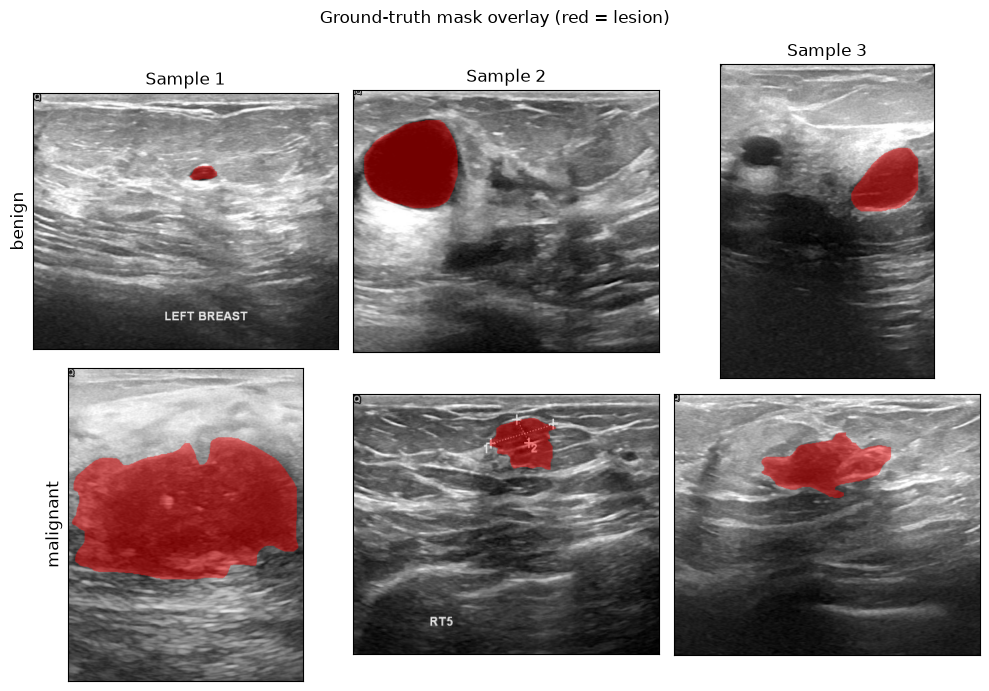

In [4]:
if samples:
    fig, axes = plt.subplots(2, 3, figsize=(10, 7))
    for r, cls in enumerate(["benign", "malignant"]):
        cls_samples = [s for s in samples if s["class"] == cls and s["mask"]][:3]
        for c, s in enumerate(cls_samples):
            img = Image.open(s["image"]).convert("RGB")
            mask = Image.open(s["mask"]).convert("L")
            ax = axes[r, c]
            ax.imshow(overlay(img, mask))
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0:
                ax.set_title(f"Sample {c+1}")
            if c == 0:
                ax.set_ylabel(cls, fontsize=12)
    plt.suptitle("Ground-truth mask overlay (red = lesion)")
    plt.tight_layout()
    plt.show()


## 2. 训练 / 验证 / 测试集划分

按类别分层划分，默认 70% 训练、15% 验证、15% 测试。

In [5]:
if samples:
    train, val, test = split_samples(samples, val_ratio=0.15, test_ratio=0.15, seed=42)
    print(f"train: {len(train)} | val: {len(val)} | test: {len(test)}")
    for name, subset in [("train", train), ("val", val), ("test", test)]:
        print(name, dict(Counter(s['class'] for s in subset)))
else:
    train, val, test = [], [], []
    print("无数据，跳过划分。")


train: 545 | val: 118 | test: 117
train {'benign': 305, 'malignant': 147, 'normal': 93}
val {'benign': 66, 'normal': 20, 'malignant': 32}
test {'benign': 66, 'malignant': 31, 'normal': 20}


## 3. 模型结构与参数量

In [6]:
img_size = 256
unet = build_model("unet", in_channels=3, out_channels=1, base_channels=32)
unetpp = build_model("unetpp", in_channels=3, out_channels=1, base_channels=32, deep_supervision=True)

print("U-Net 参数量  :", f"{count_parameters(unet):,}")
print("U-Net++ 参数量:", f"{count_parameters(unetpp):,}")

def summarize(model):
    for name, module in model.named_children():
        n = sum(p.numel() for p in module.parameters())
        print(f"  {name:<14} {module.__class__.__name__:<20} params={n:,}")

print("\nU-Net 结构:")
summarize(unet)
print("\nU-Net++ 结构:")
summarize(unetpp)

dummy = torch.randn(1, 3, img_size, img_size)
with torch.no_grad():
    out_u = unet(dummy)
    out_pp = unetpp(dummy)
print("\nU-Net 输出形状:", tuple(out_u.shape))
if isinstance(out_pp, (list, tuple)):
    print("U-Net++ 深度监督输出数量:", len(out_pp))
    print("U-Net++ 各层输出形状:", [tuple(o.shape) for o in out_pp])
else:
    print("U-Net++ 输出形状:", tuple(out_pp.shape))


U-Net 参数量  : 7,763,041
U-Net++ 参数量: 9,159,780

U-Net 结构:
  pool           MaxPool2d            params=0
  enc1           DoubleConv           params=10,208
  enc2           DoubleConv           params=55,552
  enc3           DoubleConv           params=221,696
  enc4           DoubleConv           params=885,760
  bottleneck     DoubleConv           params=3,540,992
  up4            ConvTranspose2d      params=524,544
  dec4           DoubleConv           params=1,770,496
  up3            ConvTranspose2d      params=131,200
  dec3           DoubleConv           params=442,880
  up2            ConvTranspose2d      params=32,832
  dec2           DoubleConv           params=110,848
  up1            ConvTranspose2d      params=8,224
  dec1           DoubleConv           params=27,776
  out            Conv2d               params=33

U-Net++ 结构:
  pool           MaxPool2d            params=0
  up             Upsample             params=0
  conv0_0        DoubleConv           params=10,208
  

## 4. 加载训练权重并在测试集评估

自动查找 `outputs/` 下最新的 `best.pt`。若未训练，会给出提示。

In [7]:
def find_best(model_name):
    root = ROOT / "outputs"
    if not root.exists():
        return None
    candidates = sorted(root.glob(f"{model_name}_*/best.pt"))
    return candidates[-1] if candidates else None

unet_path = find_best("unet")
unetpp_path = find_best("unetpp")
print("U-Net best.pt  :", unet_path)
print("U-Net++ best.pt:", unetpp_path)

def load_model(path):
    ckpt = torch.load(path, map_location=device)
    model = build_model(**ckpt["model_args"]).to(device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    return model

def evaluate(model, loader):
    tracker = MetricsTracker()
    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            out = model(images)
            if isinstance(out, (list, tuple)):
                out = out[-1]
            tracker.update(torch.sigmoid(out), masks)
    return tracker.compute()

results = {}
if unet_path and unetpp_path and samples:
    from src.dataset import get_dataloaders
    loaders, _ = get_dataloaders(data_root, img_size=img_size, batch_size=8)
    test_loader = loaders["test"]
    for name, path in [("U-Net", unet_path), ("U-Net++", unetpp_path)]:
        model = load_model(path)
        results[name] = evaluate(model, test_loader)
    display(pd.DataFrame(results).T)
else:
    print("未找到训练好的权重（或数据未就绪）。请先运行: python -m src.compare --epochs 100")


U-Net best.pt  : e:\jerome\MyCode\BUSI_seg\outputs\unet_20261010_201622\best.pt
U-Net++ best.pt: e:\jerome\MyCode\BUSI_seg\outputs\unetpp_20261010_184855\best.pt


,dice,iou,precision,recall,specificity,accuracy
U-Net,0.740442,0.587859,0.800611,0.688685,0.982531,0.955369
U-Net++,0.746032,0.594937,0.792610,0.704625,0.981222,0.955654


## 5. 预测结果可视化

取测试集中若干有病灶的样本，对比两个模型的预测结果。

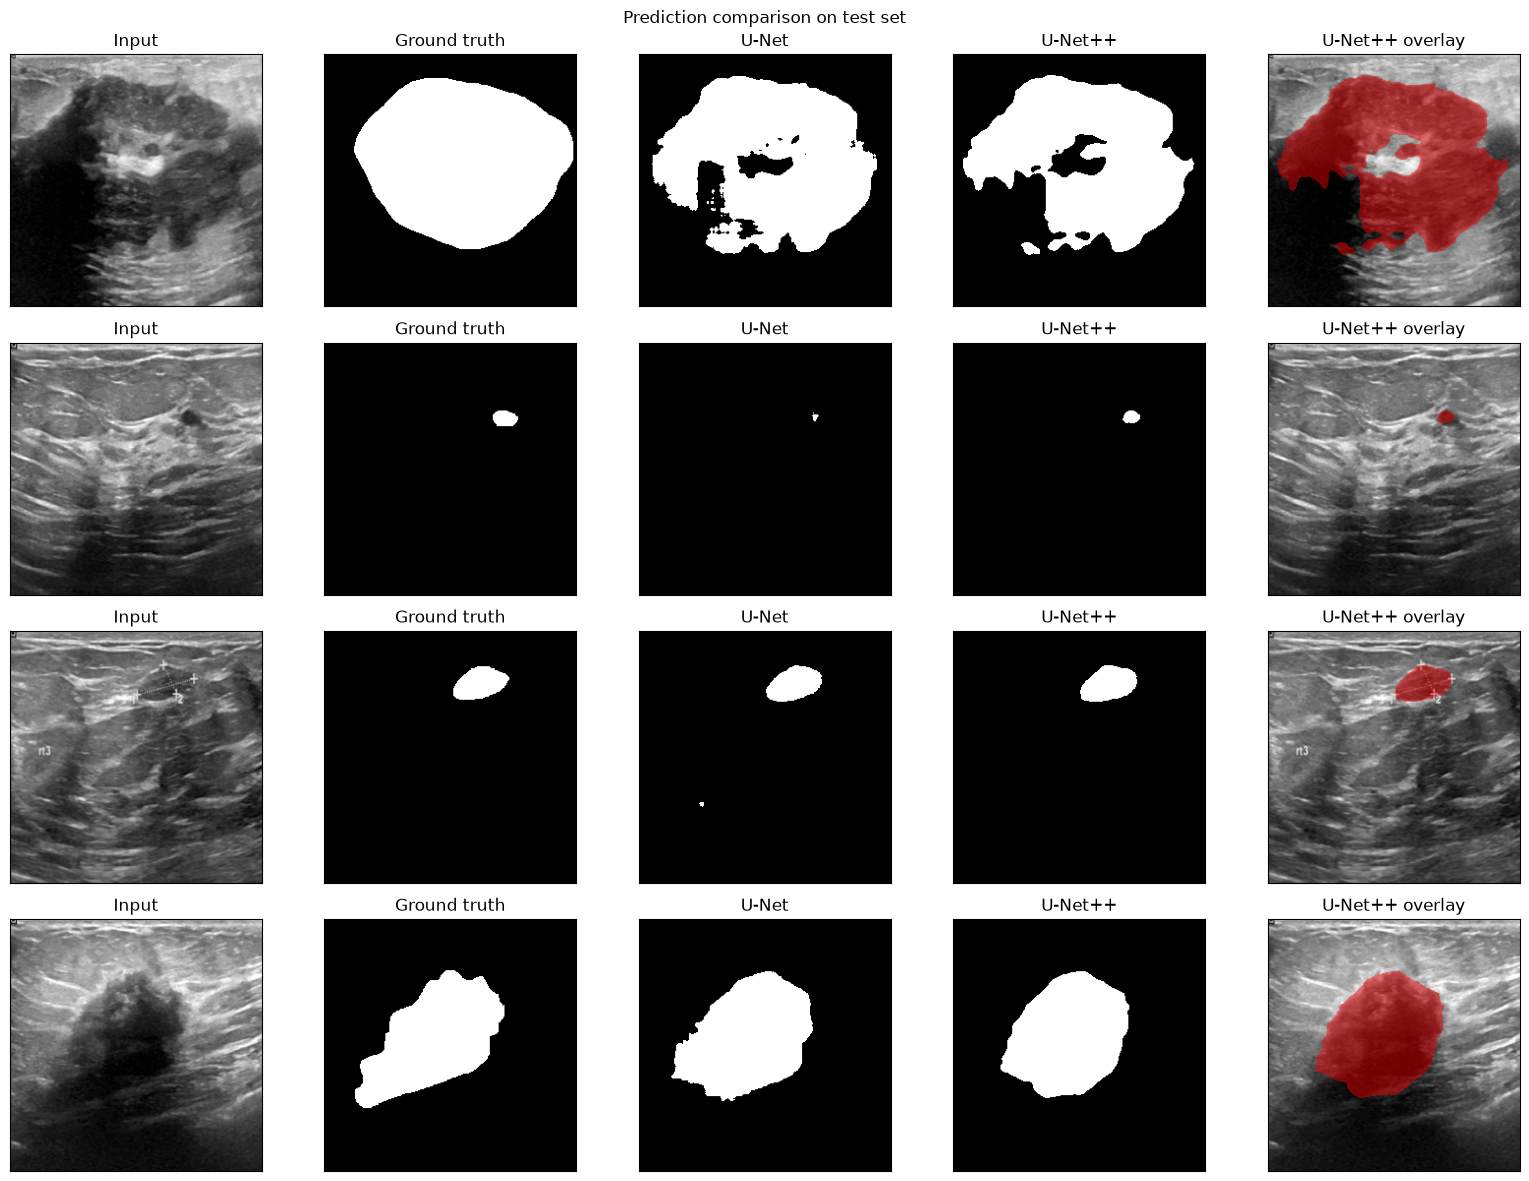

In [8]:
if results and samples:
    test_masked = [s for s in test if s["mask"]]
    show = test_masked[:4]
    ds = BUSIDataset(show, img_size=img_size, augment=False)

    model_unet = load_model(unet_path)
    model_unetpp = load_model(unetpp_path)

    def predict(model, img_tensor):
        with torch.no_grad():
            out = model(img_tensor.unsqueeze(0).to(device))
            if isinstance(out, (list, tuple)):
                out = out[-1]
            prob = torch.sigmoid(out)
        return (prob[0, 0].cpu().numpy() > 0.5).astype(np.float32)

    fig, axes = plt.subplots(len(show), 5, figsize=(16, 3 * len(show)))
    for i, s in enumerate(show):
        img_tensor, mask_tensor = ds[i]
        img = denorm(img_tensor)
        gt = mask_tensor[0].cpu().numpy()
        pred_u = predict(model_unet, img_tensor)
        pred_p = predict(model_unetpp, img_tensor)

        axes[i, 0].imshow(img); axes[i, 0].set_title("Input")
        axes[i, 1].imshow(gt, cmap="gray"); axes[i, 1].set_title("Ground truth")
        axes[i, 2].imshow(pred_u, cmap="gray"); axes[i, 2].set_title("U-Net")
        axes[i, 3].imshow(pred_p, cmap="gray"); axes[i, 3].set_title("U-Net++")
        axes[i, 4].imshow(overlay(img, pred_p)); axes[i, 4].set_title("U-Net++ overlay")
        for ax in axes[i]:
            ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle("Prediction comparison on test set")
    plt.tight_layout()
    plt.show()
else:
    print("暂无可用模型，跳过预测可视化。")


## 6. 训练曲线与性能对比

U-Net metrics.csv  : e:\jerome\MyCode\BUSI_seg\outputs\unet_20261010_173431\metrics.csv
U-Net++ metrics.csv: e:\jerome\MyCode\BUSI_seg\outputs\unetpp_20261010_184855\metrics.csv


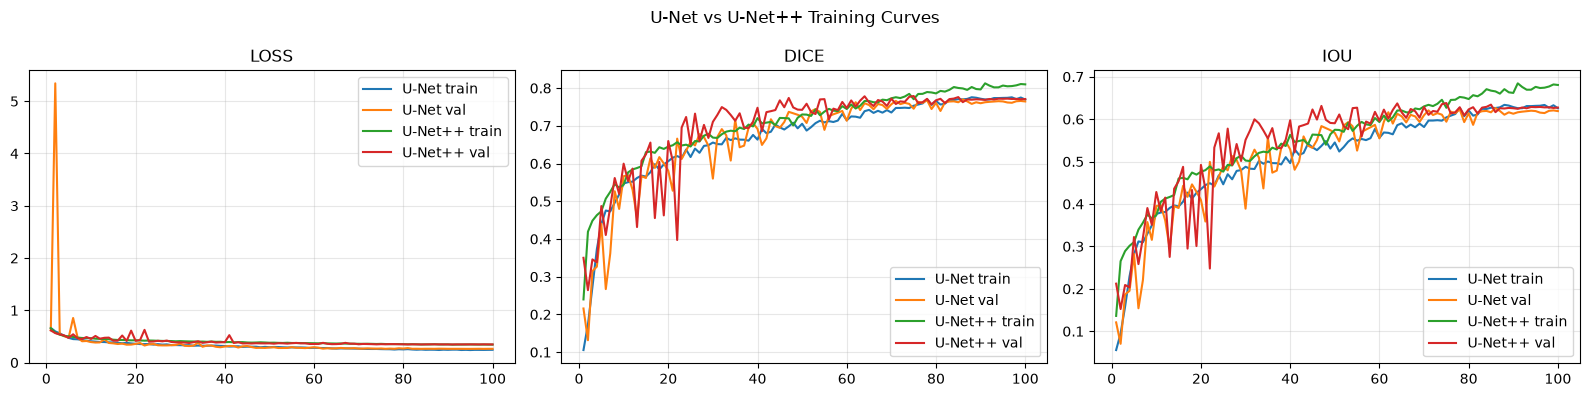

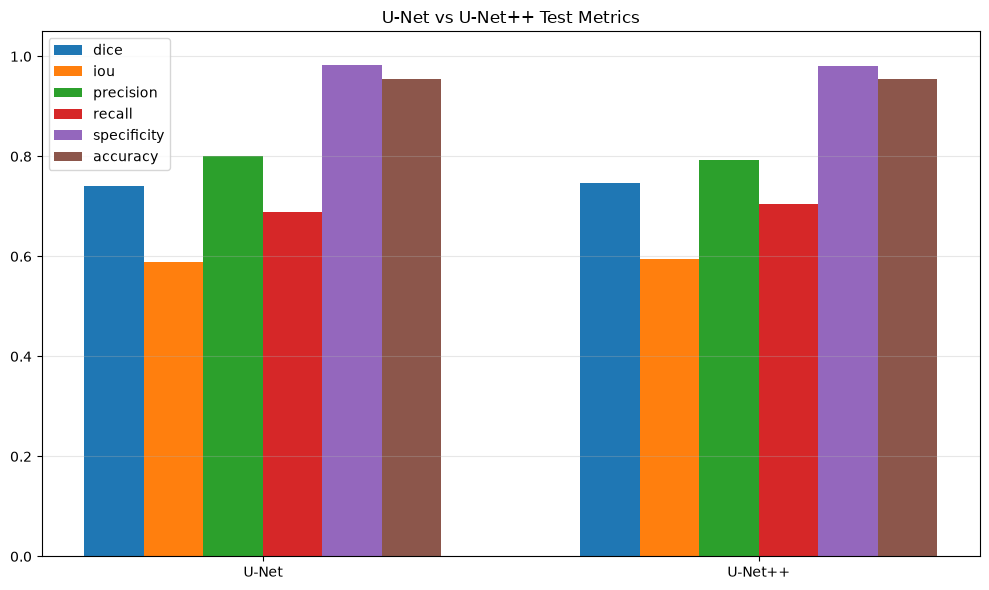

In [9]:
def latest_metrics_csv(model_name):
    root = ROOT / "outputs"
    if not root.exists():
        return None
    candidates = sorted(root.glob(f"{model_name}_*/metrics.csv"))
    return candidates[-1] if candidates else None

csv_u = latest_metrics_csv("unet")
csv_p = latest_metrics_csv("unetpp")
print("U-Net metrics.csv  :", csv_u)
print("U-Net++ metrics.csv:", csv_p)

if csv_u:
    df_u = pd.read_csv(csv_u)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, key in zip(axes, ["loss", "dice", "iou"]):
        ax.plot(df_u["epoch"], df_u[f"train_{key}"], label="U-Net train")
        ax.plot(df_u["epoch"], df_u[f"val_{key}"], label="U-Net val")
        if csv_p:
            df_p = pd.read_csv(csv_p)
            ax.plot(df_p["epoch"], df_p[f"train_{key}"], label="U-Net++ train")
            ax.plot(df_p["epoch"], df_p[f"val_{key}"], label="U-Net++ val")
        ax.set_title(key.upper())
        ax.legend()
        ax.grid(alpha=0.3)
    plt.suptitle("U-Net vs U-Net++ Training Curves")
    plt.tight_layout()
    plt.show()
else:
    print("未找到 metrics.csv，请先训练。")

if results:
    metrics = ["dice", "iou", "precision", "recall", "specificity", "accuracy"]
    models = list(results.keys())
    x = np.arange(len(models))
    width = 0.12
    fig, ax = plt.subplots(figsize=(10, 6))
    for i, m in enumerate(metrics):
        ax.bar(x + i * width, [results[mo][m] for mo in models], width, label=m)
    ax.set_xticks(x + width * (len(metrics) - 1) / 2)
    ax.set_xticklabels(models)
    ax.set_ylim(0, 1.05)
    ax.legend()
    ax.set_title("U-Net vs U-Net++ Test Metrics")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
